In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb

import os
os.environ['ENABLE_PJRT_COMPATIBILITY'] = '1'

jax.config.update('jax_platform_name', 'cpu')
os.environ['OMP_NUM_THREADS'] = str(os.cpu_count())

In [2]:
eps0 = 1e-4
def smooth_sign(x, eps = eps0):
    return 2*jax.nn.sigmoid(x/eps)-1

# def u0(x):
#     return 0.5 * (smooth_sign(x - 0.4) - smooth_sign(x - 0.6))

# def u1(x):
#     return 0

# def u2(x):
#     return 0


# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    # return -0.5*(jnp.sign(x) - 1)
    return -jnp.sin(jnp.pi*x)
def u_exact(tx):
    t, x = tx[0], tx[1]
    return u0(x-0.5*t)
vec_u_exact = vmap(u_exact)

# Boundary at x=-1
def u1(x):
    return 0

# Boundary at x=1
def u2(x):
    return 0



def res_visc(u_quad, u_t, u_x, u_xx, nu, u_exact=0):
    # print(f"u_quad shape: {u_quad.shape}")
    # print(f"u2_x shape: {u2_x.shape}")
    # print(f"u_xx shape: {u_xx.shape}")
    return u_t + u_quad*u_x - nu*u_xx
    # return u_t + 0.8*u_x - nu*u_xx
    # return jnp.zeros_like(u_quad)
    # return u_quad - u_exact

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x
    # return u_t + 0.8*u_x

# Initialize separate loss history lists for each stage
pre_loss_int_history = []
pre_loss_bc_history = []
train_loss_int_history = []
train_loss_bc_history = []

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=1e-3,
    N_bc=100,
    N_ic=200,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    project='minmax_mgnn_burgers_inti_sin',
    hidden_dims_list=[(40, 40), (40, 40), (40, 40), (40, 40)],
    init_lrs=[1e-3, 1e-3, 1e-3, 1e-3], grade_epochs=[50000, 50000, 50000, 50000], decay_rates=[1e-4, 1e-4, 1e-4, 1e-4], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
    f_opt_kh=5,
)

W0000 00:00:1751913849.537355 4114195 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1751913849.544464 4114195 service.cc:145] XLA service 0x600002bec400 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1751913849.544476 4114195 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1751913849.545372 4114195 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1751913849.545378 4114195 mps_client.cc:384] XLA backend will use up to 103078739968 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M4 Max


In [3]:
optProb.train_process()


Starting Train Stage with MGDL


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 10.07270432, lambda_bc: 10.25831032, lambda_r: 1.02087426
Grade 0, Iter 0, loss_eqn: 0.94238144, loss_ibc: 0.55618793
Grade 0, Iter 100, loss_eqn: 0.15053828, loss_ibc: 0.45651871
Grade 0, Iter 200, loss_eqn: 0.04983180, loss_ibc: 0.45420900
Grade 0, Iter 300, loss_eqn: 0.04300283, loss_ibc: 0.45444033
Grade 0, Iter 400, loss_eqn: 0.03333886, loss_ibc: 0.45428258
Grade 0, Iter 500, loss_eqn: 0.03032682, loss_ibc: 0.45433941
Grade 0, Iter 600, loss_eqn: 0.02251008, loss_ibc: 0.45418718
Grade 0, Iter 700, loss_eqn: 0.01990739, loss_ibc: 0.45408839
Grade 0, Iter 800, loss_eqn: 0.02423809, loss_ibc: 0.45398778
Grade 0, Iter 900, loss_eqn: 0.03752645, loss_ibc: 0.45411143
Grade 0, Iter 1000, lambda_ic: 9.30132675, lambda_bc: 9.48542976, lambda_r: 1.47205400
Grade 0, Iter 1000, loss_eqn: 0.03523523, loss_ibc: 0.45387083
Grade 0, Iter 1100, loss_eqn: 0.02955860, loss_ibc: 0.45493719
Grade 0, Iter 1200, loss_eqn:

grade_0_loss_eqn,▁▁█▇▆▅▅▅▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂
grade_0_loss_ibc,█▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_1_loss_eqn,█▃▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_1_loss_ibc,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_2_loss_eqn,█▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_2_loss_ibc,█▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂
second_stage_loss,▆▆▄▄▆▆▄▆▅▄▅▅▆▇▆▆█▅▅▆▇▅▄▄▅▄▂▃▄▃▂▃▂▃▄▃▃▂▁▁
second_stage_loss_ibc,▅▅▅▅▅▅▅▅▅▅▅▅▂▁▁▁▁▁▁▁▁▁▁▂▂▄▄▄▅▅▆▆▆▇▇▇▇▇██
step,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇█
grade_0_loss_eqn,0.08443
grade_0_loss_ibc,6e-05


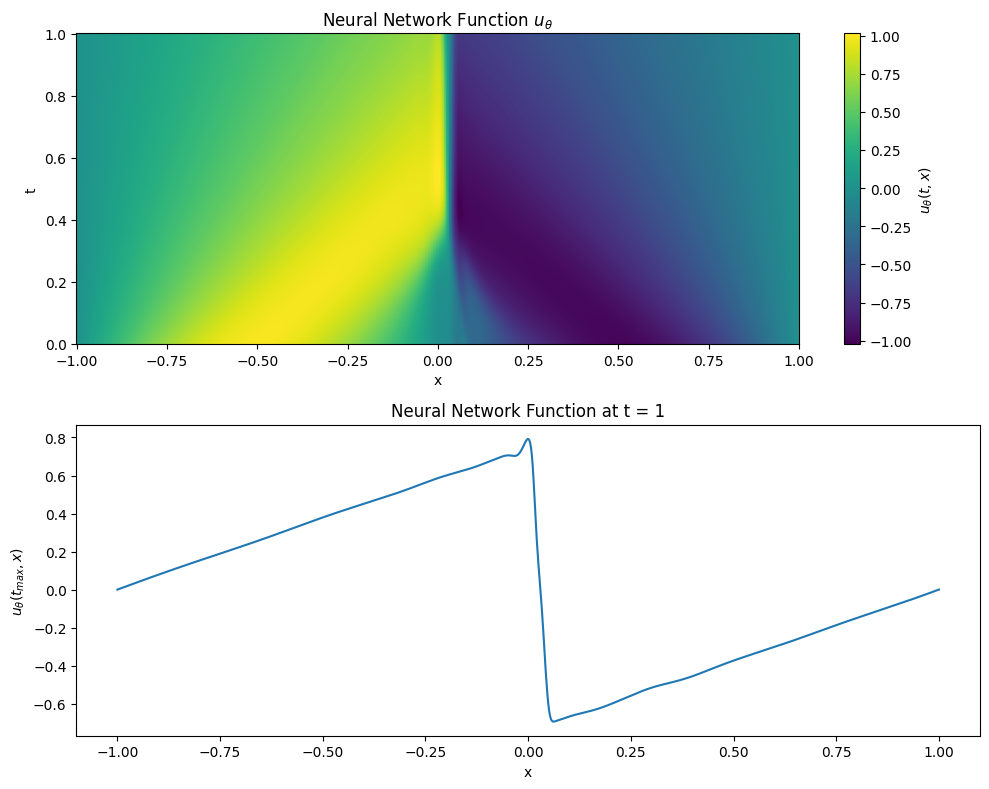

In [6]:
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state


In [5]:
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state


Array([0.2923711 , 0.29203176, 0.29168776, 0.2913392 , 0.29098585,
       0.29062802, 0.2902654 , 0.2898982 , 0.28952628, 0.28914982,
       0.2887686 , 0.28838274, 0.28799227, 0.28759715, 0.28719744,
       0.28679317, 0.2863842 , 0.2859706 , 0.2855525 , 0.28512976,
       0.28470236, 0.28427052, 0.28383407, 0.28339309, 0.28294763,
       0.28249764, 0.28204322, 0.2815842 , 0.28112078, 0.28065288,
       0.28018066, 0.27970397, 0.27922288, 0.27873752, 0.27824774,
       0.27775362, 0.2772553 , 0.27675265, 0.2762458 , 0.2757347 ,
       0.2752194 , 0.2747    , 0.2741764 , 0.27364865, 0.27311692,
       0.27258104, 0.27204132, 0.27149743, 0.27094972, 0.270398  ,
       0.26984248, 0.26928294, 0.26871967, 0.2681527 , 0.2675819 ,
       0.26700744, 0.26642928, 0.26584744, 0.26526204, 0.2646731 ,
       0.26408058, 0.2634847 , 0.26288524, 0.2622824 , 0.26167625,
       0.26106676, 0.26045406, 0.25983813, 0.25921902, 0.25859672,
       0.25797138, 0.2573429 , 0.25671145, 0.256077  , 0.25543

In [6]:
optProb.loss_fn_ic(params)

Array(0.28839403, dtype=float32)

In [9]:
list(params)[0]

Array(0.1, dtype=float32, weak_type=True)

In [9]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = os.path.join('..', 'data', f'train_model_{timestamp}.pkl')

In [8]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = os.path.join('data', f'train_model_{timestamp}.pkl')
optProb.save_model(model_path)
print(f"Train model saved to {model_path}")

Train model saved to data/train_model_20250708_110939.pkl


In [7]:
ls

 Volume in drive C has no label.
 Volume Serial Number is C860-DE6E

 Directory of C:\Users\hao6li\Projects\NN-HCL\Code

07/07/2025  08:58 PM    <DIR>          .
07/03/2025  05:58 PM    <DIR>          ..
07/03/2025  05:58 PM             6,148 .DS_Store
07/05/2025  10:15 PM    <DIR>          .ipynb_checkpoints
07/06/2025  03:37 PM    <DIR>          __pycache__
07/03/2025  05:58 PM           102,064 0-Burgers.ipynb
07/03/2025  05:58 PM         1,001,248 Burgers_1D_rarefaction_shock.ipynb
07/03/2025  06:28 PM           780,087 Burgers_1D_rarefaction_wave.ipynb
07/03/2025  05:58 PM           298,110 Burgers_1D_standing_shock.ipynb
07/05/2025  10:19 PM           850,088 Burgers_1D_traveling_shock.ipynb
07/03/2025  05:58 PM         2,977,085 Burgers_bdry_int_loss.ipynb
07/03/2025  05:58 PM           829,005 Burgers_rarefaction_shock_test.ipynb
07/03/2025  05:58 PM    <DIR>          data
07/03/2025  05:58 PM           744,515 HCL_1D.ipynb
07/03/2025  05:58 PM         1,612,266 HCL_1D_triangle

In [18]:
optProb.save_model(model_path)

In [16]:
os.makedirs(os.path.dirname(model_path), exist_ok=True)

In [15]:
model_path = os.path.join('data', f'train_model_{timestamp}.pkl')

In [5]:
import matplotlib.pyplot as plt
import jax.numpy as jnp

def plot_u_theta(model, params=None, M_t=100, M_x=100, t_min=0.0, t_max=1.0, x_min=0.0, x_max=1.0):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max],
    and include a 1D plot of u_theta at t = t_max.

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 100).
        M_x: Number of grid points in the x-direction (default: 100).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 1.0).
        x_min: Minimum value for x (default: 0.0).
        x_max: Maximum value for x (default: 1.0).
    """
    # Create a grid for t and x over the specified ranges
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Evaluate u_theta on the grid points
    if params is None:
        u_values = model.forward(tx_points)
    else:
        u_values = model(params, tx_points)  # Shape: (M_t * M_x, 1)
    u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # 2D color mesh plot
    pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    fig.colorbar(pcm, ax=ax1, label='$u_\\theta(t, x)$')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_title('Neural Network Function $u_\\theta$')

    # 1D plot at t = t_max
    ax2.plot(x_grid, u_values[-1, :])
    ax2.set_xlabel('x')
    ax2.set_ylabel('$u_\\theta(t_{max}, x)$')
    ax2.set_title(f'Neural Network Function at t = {t_max}')

    # Adjust layout and display
    plt.tight_layout()
    plt.show()

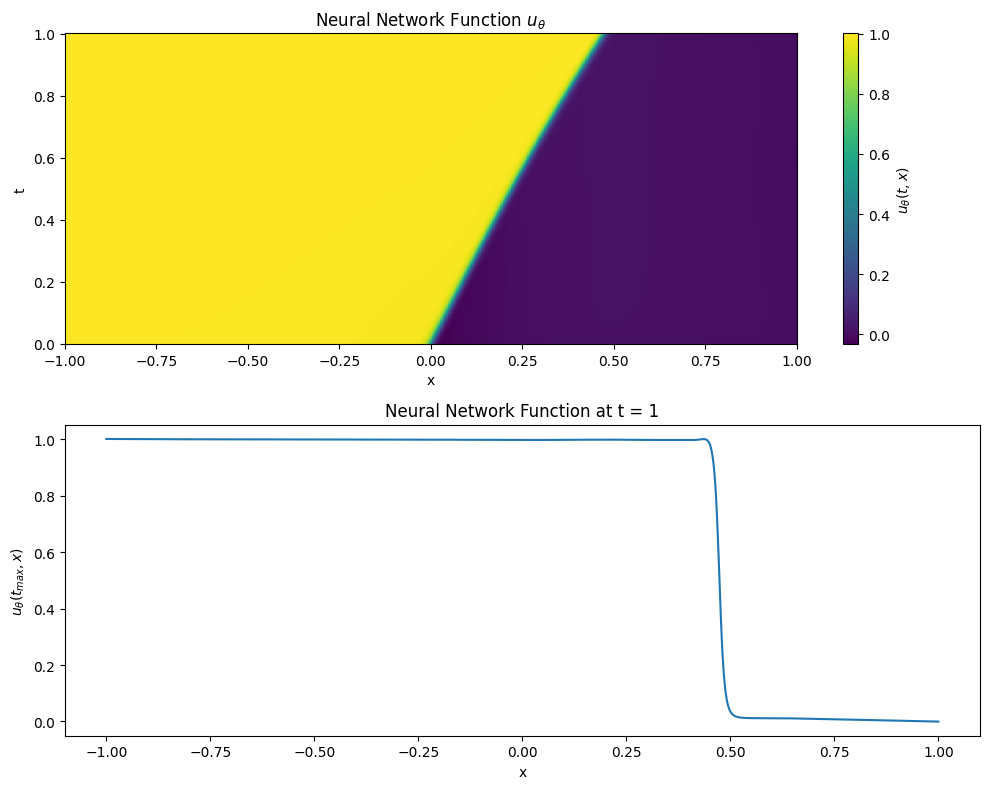

In [31]:
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state


In [3]:
print(os.environ.get('ENABLE_PJRT_COMPATIBILITY'))

1
